In [15]:
import json
from pathlib import Path
import zipfile  

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix

In [2]:
"""
Inspect the WiCount dataset (ESP32-S3 CSI, people count 0-3).

Goal: check the things the dataset card does NOT tell us:
  - how many CSV files per class (this decides how we can split train/test)
  - real packet rate
  - which MAC addresses appear (is the transmitter a router or an ESP32?)
  - does each CSI row really have 104 numbers (52 complex subcarriers)?

"""


# 1. Download the dataset (cached after the first run)
zip_path = hf_hub_download(
    repo_id="RS2002/WiCount",
    repo_type="dataset",         
    filename="WiCount.zip",
    local_dir="../data/raw/WiCount",
)

out = Path("../data/raw/WiCount/extracted")
with zipfile.ZipFile(zip_path) as z:
    z.extractall(out)



def parse_csi(cell):
    """The 'data' column holds a list of numbers stored as text."""
    if isinstance(cell, str):
        try:
            return json.loads(cell)
        except json.JSONDecodeError:
            return [int(x) for x in cell.strip("[] ").split(",") if x.strip()]
    return list(cell)


# 2. Look at every CSV file
records = []
macs_per_class = {}
for csv_path in sorted(out.rglob("*.csv")):
    label = csv_path.parent.name          # folder name = number of people
    df = pd.read_csv(csv_path)

    # duration from the 'timestamp' column (UTC+8 time of collection)
    ts = pd.to_datetime(df["timestamp"], errors="coerce").dropna()
    seconds = (ts.iloc[-1] - ts.iloc[0]).total_seconds() if len(ts) > 1 else np.nan

    # length of the CSI vector in the first row
    csi_len = len(parse_csi(df["data"].iloc[0]))

    # MAC address column (name may differ, so search for it)
    mac_cols = [c for c in df.columns if "mac" in c.lower()]
    if mac_cols:
        macs_per_class.setdefault(label, set()).update(df[mac_cols[0]].unique())

    records.append({
        "class": label,
        "file": csv_path.name,
        "rows": len(df),
        "seconds": round(seconds, 1),
        "rate_hz": round(len(df) / seconds, 1) if seconds and seconds > 0 else np.nan,
        "csi_len": csi_len,
        "rssi_mean": round(df["rssi"].mean(), 1),
    })

info = pd.DataFrame(records)

# 3. Print the summary
print("\n=== Per file ===")
print(info.to_string(index=False))

print("\n=== Per class ===")
summary = info.groupby("class").agg(
    files=("file", "count"),
    total_rows=("rows", "sum"),
    total_minutes=("seconds", lambda s: round(s.sum() / 60, 1)),
    mean_rate_hz=("rate_hz", "mean"),
    rssi_mean=("rssi_mean", "mean"),
)
print(summary.to_string())

print("\n=== CSI vector lengths seen ===", sorted(info["csi_len"].unique()))
print("\n=== MAC addresses per class ===")
for label, macs in sorted(macs_per_class.items()):
    print(label, sorted(macs))


=== Per file ===
class                              file  rows  seconds  rate_hz  csi_len  rssi_mean
    0 2023-12-21_19-23-53-985_104_1.csv  5218     60.0     87.0      104      -27.2
    1 2023-12-21_19-27-21-930_104_1.csv  4780     60.0     79.7      104      -28.0
    1 2023-12-21_19-31-17-706_104_1.csv  5189     60.0     86.5      104      -27.9
    1 2023-12-21_19-34-42-783_104_1.csv  5234     60.0     87.2      104      -27.8
    1 2023-12-21_19-37-36-861_104_1.csv  5163     60.0     86.1      104      -27.7
    1 2023-12-21_19-40-12-110_104_1.csv  5421     60.0     90.4      104      -27.6
    1 2023-12-21_19-42-28-267_104_1.csv  5644     60.0     94.1      104      -27.6
    1 2023-12-21_19-45-07-501_104_1.csv  5128     60.0     85.5      104      -27.9
    2 2023-12-21_19-47-14-669_104_1.csv  5376     60.0     89.6      104      -29.1
    2 2023-12-21_19-49-37-940_104_1.csv  5307     60.0     88.5      104      -28.4
    2 2023-12-21_19-54-01-269_104_1.csv  5141     60.0    

In [3]:
N_SUB = 52  # number of complex subcarriers in the CSI vector

def load_csv(path):
    """Return the dataframe and amplitude array"""
    df = pd.read_csv(path, usecols=["data", "local_timestamp", "rssi"])
    csi = np.array([json.loads(s) for s in df["data"]], dtype=np.float32)
    assert csi.shape[1] == 2 * N_SUB, f"{path.name}: expected 104 values, got {csi.shape[1]}"
    comp = csi[:, 0::2] + (1j * csi[:, 1::2])
    return {"amp": np.abs(comp).astype(np.float32),
            "lts": df["local_timestamp"].to_numpy(dtype=np.int64),
            "rssi": df["rssi"].to_numpy()}

files = sorted(out.rglob("*.csv"))
data = {}
for p in files:
    d= load_csv(p)
    data[p.name] = {
        "label": int(p.parent.name),
        "amp": d["amp"],
        "lts": d["lts"],
        "rssi": d["rssi"]
    }

print(len(data), "files loaded")


15 files loaded


In [4]:
amp_df = pd.DataFrame(
    data[files[0].name]["amp"],
    columns=[f"Subcarrier_{i+1}" for i in range(data[files[0].name]["amp"].shape[1])]
)

display(amp_df.head(10))


,Subcarrier_1,Subcarrier_2,Subcarrier_3,Subcarrier_4,Subcarrier_5,Subcarrier_6,Subcarrier_7,Subcarrier_8,Subcarrier_9,Subcarrier_10,...,Subcarrier_43,Subcarrier_44,Subcarrier_45,Subcarrier_46,Subcarrier_47,Subcarrier_48,Subcarrier_49,Subcarrier_50,Subcarrier_51,Subcarrier_52
0,9.486833,8.602325,9.219544,10.816654,11.661903,13.416409,14.764824,15.264338,16.124516,16.643316,...,19.209373,14.866069,11.401754,8.544003,8.062258,9.433981,12.041595,13.453625,14.866069,15.556349
1,9.899495,9.433981,9.486833,10.198039,12.000000,13.000000,15.033297,15.000000,16.000000,16.000000,...,18.248287,14.035668,10.049876,8.062258,8.062258,10.198039,13.000000,14.000000,16.031219,16.031219
2,8.602325,8.544003,9.219544,10.000000,11.045361,13.038405,14.142136,14.035668,15.033297,15.033297,...,17.262676,14.142136,10.000000,7.615773,7.211102,8.246211,10.049876,12.000000,13.000000,13.000000
3,9.055386,9.055386,9.486833,11.180340,12.529964,13.038404,14.422205,15.264338,16.124516,16.124516,...,18.027756,13.928389,10.295630,7.810249,7.071068,8.246211,9.848858,11.661903,13.038404,13.038404
4,9.219544,8.602325,8.944272,10.440307,12.165524,13.152946,14.142136,15.132746,15.297058,15.297058,...,16.763054,13.341663,9.000000,6.324555,6.403124,8.246211,10.049876,12.041595,13.000000,13.038405
5,8.246211,8.062258,8.544003,9.433981,11.401754,12.806249,14.212670,13.601470,15.000000,15.811389,...,17.720043,13.928389,10.816654,7.810249,8.246211,9.055386,11.401754,12.999999,14.317821,14.317821
6,8.485281,8.062258,8.246211,9.055386,10.049876,11.180340,13.152946,13.152946,14.142136,14.142136,...,17.029385,13.000000,9.219544,7.810249,7.615773,10.049876,12.041595,13.038405,15.132746,15.033297
7,9.219544,8.062258,8.246211,9.000000,10.049876,11.180340,12.165524,13.152946,14.142136,14.142136,...,17.117243,13.000000,9.219544,7.211102,7.615773,9.055386,12.000000,13.038405,15.033297,15.033297
8,8.485281,8.602325,8.544003,9.055386,10.000000,11.000000,12.041595,12.000000,13.000000,14.035668,...,17.029385,13.000000,9.219544,7.211102,7.615773,9.000000,11.045361,13.152946,14.142136,14.142136
9,8.246211,7.615773,7.810249,9.219544,10.000000,11.661903,12.529964,12.529964,12.529964,13.038404,...,16.643316,12.529964,9.486833,7.071068,7.211102,8.602325,11.180340,12.083046,14.317821,14.317821


In [5]:
WRAP = 2**32  # local_timestamp wraps around at 2^32
rows = []
for name, d in data.items():
    gaps_ms = (np.diff(d["lts"]) % WRAP) / 1000
    dur_s = gaps_ms.sum() / 1000
    rows.append({"label": d["label"], "file": name[:19], "packets": len(d["amp"]),
                 "duration_s": round(dur_s, 1), "rate_hz": round(len(d["amp"]) / dur_s, 1),
                 "zero_gaps": int((gaps_ms == 0).sum()),
                 "p50_gap_ms": round(np.median(gaps_ms), 1),
                 "p99_gap_ms": round(np.percentile(gaps_ms, 99), 1),
                 "max_gap_ms": round(gaps_ms.max(), 1),
                 "rssi_mean": round(d["rssi"].mean(), 1)})
raw_table = pd.DataFrame(rows)
print(raw_table.to_string(index=False))

 label                file  packets  duration_s  rate_hz  zero_gaps  p50_gap_ms  p99_gap_ms  max_gap_ms  rssi_mean
     0 2023-12-21_19-23-53     5218        60.0     87.0          0        12.0        20.4        38.7      -27.2
     1 2023-12-21_19-27-21     4780        60.0     79.7          0        12.0        32.8       101.4      -28.0
     1 2023-12-21_19-31-17     5189        60.0     86.5          0        12.0        20.3        35.6      -27.9
     1 2023-12-21_19-34-42     5234        60.0     87.2          0        12.0        20.3        39.4      -27.8
     1 2023-12-21_19-37-36     5163        60.0     86.1          0        12.0        20.5        40.7      -27.7
     1 2023-12-21_19-40-12     5421        60.0     90.4          0        12.0        20.0        36.0      -27.6
     1 2023-12-21_19-42-28     5644        60.0     94.1          0        12.0        19.7        34.3      -27.6
     1 2023-12-21_19-45-07     5128        60.0     85.5          0        12.0 

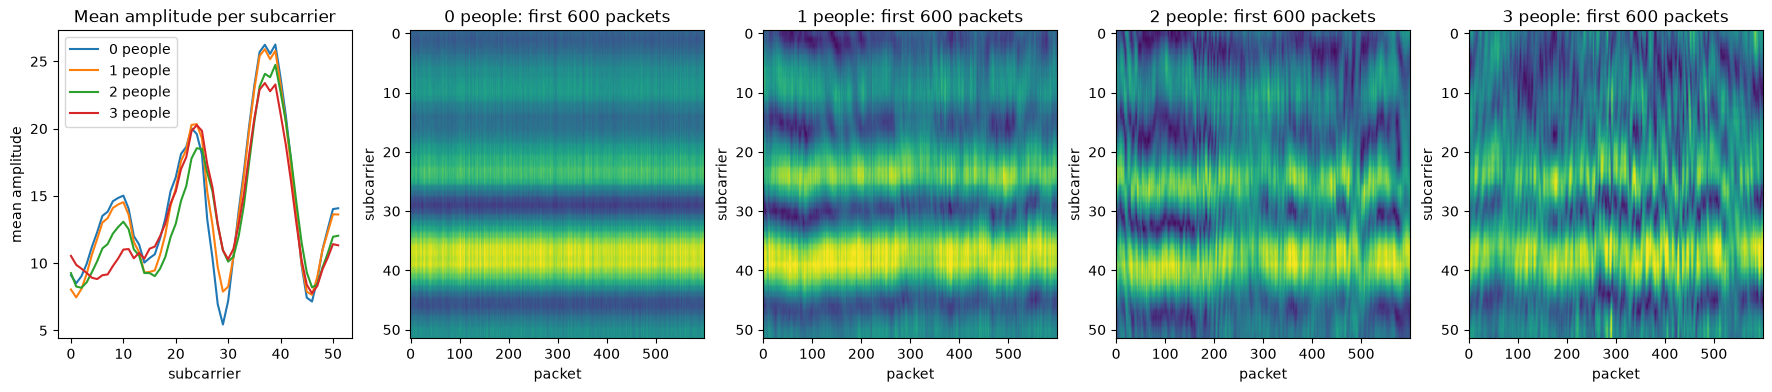

In [6]:
first = {}                                   # first file of each class
for name, d in data.items():
    first.setdefault(d["label"], d)

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for lab, d in sorted(first.items()):
    axes[0].plot(d["amp"].mean(axis=0), label=f"{lab} people")
axes[0].set_xlabel("subcarrier"); axes[0].set_ylabel("mean amplitude"); axes[0].legend()
axes[0].set_title("Mean amplitude per subcarrier")
vmax = max(np.percentile(d["amp"], 99) for d in first.values())
for ax, (lab, d) in zip(axes[1:], sorted(first.items())):
    ax.imshow(d["amp"][:600].T, aspect="auto", vmin=0, vmax=vmax)
    ax.set_title(f"{lab} people: first 600 packets"); ax.set_xlabel("packet"); ax.set_ylabel("subcarrier")
# plt.tight_layout(); plt.savefig(FIGS / "01_signal_overview.png", dpi=150); plt.show()

In [7]:
all_amp = np.concatenate([d["amp"] for d in data.values()])
print("dead subcarriers (std < 1e-3):", np.where(all_amp.std(axis=0) < 1e-3)[0])

for name, d in data.items():
    pkt_mean = d["amp"].mean(axis=1)
    bad = np.where(pkt_mean < 0.5 * np.median(pkt_mean))[0]
    if len(bad):
        print(f"{name[:19]}: {len(bad)} glitch packet(s) at rows {bad[:10]}")

dead subcarriers (std < 1e-3): []
2023-12-21_19-27-21: 1 glitch packet(s) at rows [3190]


In [8]:
SESSION_ID = "wicount_20231221"

def to_common_format(name, d):
    amp = d["amp"]
    assert amp.shape[1] == N_SUB and not np.isnan(amp).any(), f"{name}: bad amplitude"

    # time in seconds; "% WRAP" handles a counter wrap-around
    time_s = np.concatenate([[0.0], np.cumsum(np.diff(d["lts"]) % WRAP)]) / 1e6

    # drop glitch packets (board version: compare with a running median, not the file median)
    pkt_mean = amp.mean(axis=1)
    keep = pkt_mean >= 0.5 * np.median(pkt_mean)
    amp, time_s = amp[keep], time_s[keep]

    # segments: a gap longer than GAP_LIMIT_S starts a new segment (windows never cross it)
    breaks = np.where(np.diff(time_s) > 0.150)[0] + 1
    seg_start = np.concatenate([[0], breaks])
    seg_end = np.concatenate([breaks, [len(time_s)]])

    return {"amp": amp, "time_s": time_s, "label": d["label"], "file_id": name,
            "session_id": SESSION_ID, "seg_start": seg_start, "seg_end": seg_end,
            "n_dropped": int((~keep).sum())}

clean = {name: to_common_format(name, d) for name, d in data.items()}

out = Path("../data/processed/wicount")
out.mkdir(parents=True, exist_ok=True)
for name, c in clean.items():
    np.savez_compressed(out / name.replace(".csv", ".npz"),
                        amp=c["amp"], time_s=c["time_s"], label=c["label"],
                        file_id=c["file_id"], session_id=c["session_id"],
                        seg_start=c["seg_start"], seg_end=c["seg_end"])

print("files saved:", len(clean), "| packets dropped:", sum(c["n_dropped"] for c in clean.values()))
for name, c in clean.items():
    if len(c["seg_start"]) > 1:
        print(f"{name[:19]} (label {c['label']}) split into {len(c['seg_start'])} segments")


files saved: 15 | packets dropped: 1
2023-12-21_20-07-25 (label 3) split into 2 segments


In [9]:
rows = []
for name, c in clean.items():
    gaps_ms = np.diff(c["time_s"]) * 1000
    rows.append({"label": c["label"], "file": name[:19],
                 "packets": len(c["amp"]), "dropped": c["n_dropped"],
                 "duration_s": round(c["time_s"][-1], 1),
                 "rate_hz": round(len(c["amp"]) / c["time_s"][-1], 1),
                 "p99_gap_ms": round(np.percentile(gaps_ms, 99), 1),
                 "max_gap_ms": round(gaps_ms.max(), 1)})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
print("\ntotal dropped:", summary["dropped"].sum())

 label                file  packets  dropped  duration_s  rate_hz  p99_gap_ms  max_gap_ms
     0 2023-12-21_19-23-53     5218        0        60.0     87.0        20.4        38.7
     1 2023-12-21_19-27-21     4779        1        60.0     79.7        32.8       101.4
     1 2023-12-21_19-31-17     5189        0        60.0     86.5        20.3        35.6
     1 2023-12-21_19-34-42     5234        0        60.0     87.2        20.3        39.4
     1 2023-12-21_19-37-36     5163        0        60.0     86.1        20.5        40.7
     1 2023-12-21_19-40-12     5421        0        60.0     90.4        20.0        36.0
     1 2023-12-21_19-42-28     5644        0        60.0     94.1        19.7        34.3
     1 2023-12-21_19-45-07     5128        0        60.0     85.5        21.8        38.4
     2 2023-12-21_19-47-14     5376        0        60.0     89.6        20.0        32.1
     2 2023-12-21_19-49-37     5307        0        60.0     88.5        20.0        31.4
     2 202

In [10]:
WINDOW_SIZES = [128, 256, 512, 600] 

def make_index(win, overlap=0.5):
    step = int(win * (1 - overlap))
    rows = []
    for name, c in clean.items():
        for s, e in zip(c["seg_start"], c["seg_end"]):        # windows stay inside one segment
            for i in range(s, e - win + 1, step):
                rows.append({"file_id": name, "label": c["label"], "start": i, "win": win,
                             "t_start": c["time_s"][i], "t_end": c["time_s"][i + win - 1]})
    idx = pd.DataFrame(rows)
    idx["duration_s"] = idx["t_end"] - idx["t_start"]
    return idx

def get_windows(idx):
    """Build the array X [N, win, 52] from an index table."""
    return np.stack([clean[f]["amp"][s:s + w] for f, s, w in
                     zip(idx["file_id"], idx["start"], idx["win"])]).astype(np.float32)

index = {w: make_index(w) for w in WINDOW_SIZES}

summary = []
for w, idx in index.items():
    idx.to_csv(out / f"windows_index_{w}.csv", index=False)
    counts = idx["label"].value_counts().sort_index()
    summary.append({"win_packets": w, "windows": len(idx),
                    **{f"class_{k}": v for k, v in counts.items()},
                    "min_files_per_window": idx.groupby("file_id").size().min(),
                    "dur_median_s": round(idx["duration_s"].median(), 2),
                    "dur_min_s": round(idx["duration_s"].min(), 2),
                    "dur_max_s": round(idx["duration_s"].max(), 2)})
print(pd.DataFrame(summary).rename(columns={"min_files_per_window": "min_windows_per_file"}).to_string(index=False))

 win_packets  windows  class_0  class_1  class_2  class_3  min_windows_per_file  dur_median_s  dur_min_s  dur_max_s
         128     1205       80      561      490       74                    73          1.44       1.28       2.33
         256      592       39      276      241       36                    36          2.90       2.60       4.34
         512      286       19      134      117       16                    16          5.82       5.26       8.16
         600      240       16      112       98       14                    14          6.82       6.15       9.37


In [11]:
def window_features(W):
    """W: one window [win packets, 52 subcarriers] -> dict of features."""
    med = np.median(W, axis=0)                             # per subcarrier
    q75, q25 = np.percentile(W, [75, 25], axis=0)
    iqr = q75 - q25
    std_t = W.std(axis=0)
    dW = np.diff(W, axis=0)                                # packet-to-packet change
    turb = W.std(axis=1) / (W.mean(axis=1) + 1e-6)         # spread across subcarriers, per packet
    return {
        # fluctuation over time
        "std_mean": std_t.mean(), "std_max": std_t.max(),
        "mad_mean": np.median(np.abs(W - med), axis=0).mean(),
        "iqr_mean": iqr.mean(), "iqr_max": iqr.max(),
        "diff_mean": np.abs(dW).mean(),
        "pkt_dist_median": np.median(np.linalg.norm(dW, axis=1)),   # all 52 values at once
        "range_mean": (W.max(axis=0) - W.min(axis=0)).mean(),
        # spread across subcarriers (gain-independent)
        "turb_mean": turb.mean(), "turb_std": turb.std(),
        # level - NOT baseline-relative on WiCount (see Cell 10)
        "level_median": np.median(W),
        "level_p10": np.percentile(W, 10), "level_p90": np.percentile(W, 90),
    }

features = {}
for w, idx in index.items():
    X = get_windows(idx)
    f = pd.DataFrame([window_features(Wi) for Wi in X])
    features[w] = pd.concat([idx.reset_index(drop=True), f], axis=1)
    features[w].to_csv(out / f"features_{w}.csv", index=False)
    print(f"win {w}: {f.shape[0]} windows x {f.shape[1]} features saved")

FEATURE_COLS = list(f.columns)
print("\nmedian per class (win 128):")
print(features[128].groupby("label")[FEATURE_COLS].median().round(3).T.to_string())

win 128: 1205 windows x 13 features saved
win 256: 592 windows x 13 features saved
win 512: 286 windows x 13 features saved
win 600: 240 windows x 13 features saved

median per class (win 128):
label                 0          1       2          3
std_mean          0.980   1.917000   2.492   2.906000
std_max           1.553   2.871000   3.687   4.364000
mad_mean          0.671   1.273000   1.650   1.963000
iqr_mean          1.330   2.553000   3.359   3.962000
iqr_max           2.236   4.125000   5.385   6.399000
diff_mean         1.099   1.118000   1.087   1.192000
pkt_dist_median   7.984   8.632000   8.793   9.742000
range_mean        4.390  10.041000  11.927  13.923000
turb_mean         0.376   0.402000   0.427   0.417000
turb_std          0.008   0.049000   0.066   0.076000
level_median     13.379  13.038000  12.530  12.767000
level_p10         8.062   7.616000   6.708   6.708000
level_p90        23.087  23.021999  22.472  22.023001


Text(0.5, 0.98, 'Window features per class (WiCount, one session, 128-packet windows)')

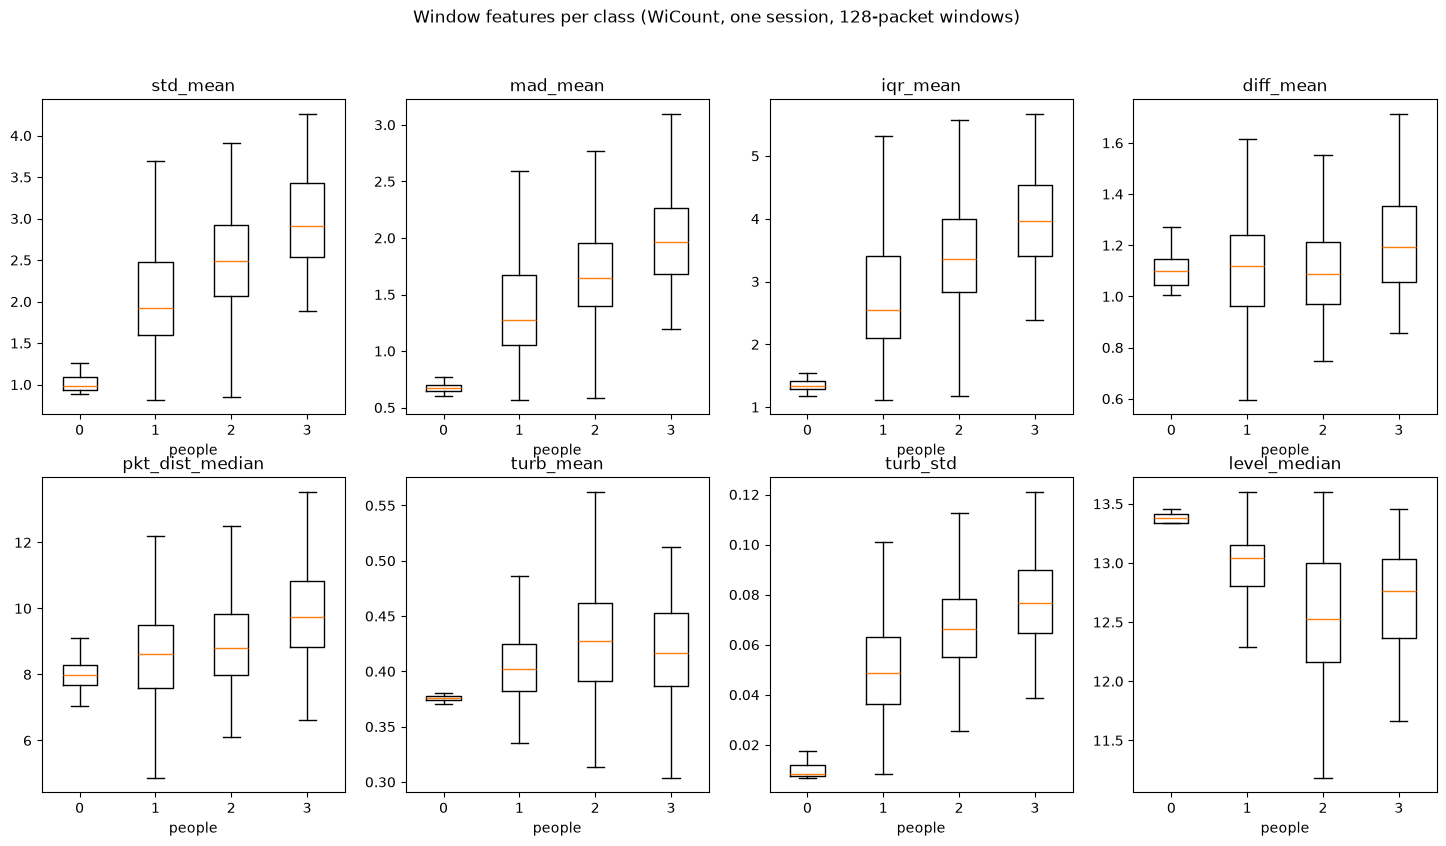

In [12]:

WIN_SHOW = 128
cols = ["std_mean", "mad_mean", "iqr_mean", "diff_mean",
        "pkt_dist_median", "turb_mean", "turb_std", "level_median"]
df = features[WIN_SHOW]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cols):
    ax.boxplot([df.loc[df["label"] == k, col] for k in sorted(df["label"].unique())],
               tick_labels=sorted(df["label"].unique()), showfliers=False)
    ax.set_title(col); ax.set_xlabel("people")
fig.suptitle(f"Window features per class (WiCount, one session, {WIN_SHOW}-packet windows)")
# plt.tight_layout(); plt.savefig(FIGS / f"02_feature_boxplots_{WIN_SHOW}.png", dpi=150); plt.show()

In [13]:
# WIN_SHOW = 600
# cols = ["std_mean", "mad_mean", "iqr_mean", "diff_mean",
#         "pkt_dist_median", "turb_mean", "turb_std", "level_median"]
# df = features[WIN_SHOW]
# fig, axes = plt.subplots(2, 4, figsize=(18, 9))
# for ax, col in zip(axes.ravel(), cols):
#     ax.boxplot([df.loc[df["label"] == k, col] for k in sorted(df["label"].unique())],
#                tick_labels=sorted(df["label"].unique()), showfliers=False)
#     ax.set_title(col); ax.set_xlabel("people")
# fig.suptitle(f"Window features per class (WiCount, one session, {WIN_SHOW}-packet windows)")

longest window (s) per file, win 128:
file_id
2023-12-21_19-23-53    1.64
2023-12-21_19-27-21    2.33
2023-12-21_19-31-17    1.61
2023-12-21_19-34-42    1.56
2023-12-21_19-37-36    1.62
2023-12-21_19-40-12    1.50
2023-12-21_19-42-28    1.52
2023-12-21_19-45-07    1.67
2023-12-21_19-47-14    1.53
2023-12-21_19-49-37    1.56
2023-12-21_19-54-01    1.60
2023-12-21_19-56-22    1.51
2023-12-21_20-02-00    1.60
2023-12-21_20-04-39    1.57
2023-12-21_20-07-25    1.62


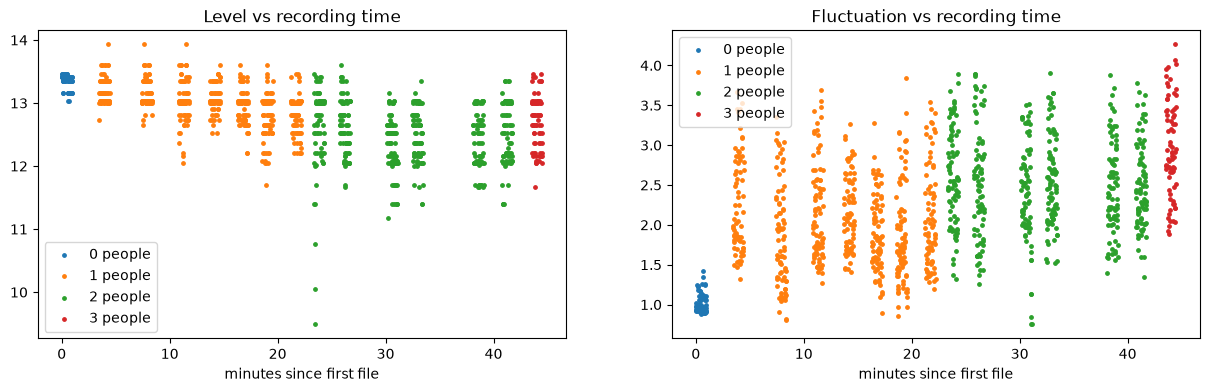

In [14]:
df = features[128].copy()
start = pd.to_datetime(df["file_id"].str[:19], format="%Y-%m-%d_%H-%M-%S")
df["minute"] = (start - start.min()).dt.total_seconds() / 60 + df["t_start"] / 60

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for lab, g in df.groupby("label"):
    axes[0].scatter(g["minute"], g["level_median"], s=6, label=f"{lab} people")
    axes[1].scatter(g["minute"], g["std_mean"], s=6, label=f"{lab} people")
axes[0].set_title("Level vs recording time"); axes[1].set_title("Fluctuation vs recording time")
for ax in axes:
    ax.set_xlabel("minutes since first file"); ax.legend()
# plt.tight_layout(); plt.savefig(FIGS / "03_drift_check.png", dpi=150); plt.show()

print("longest window (s) per file, win 128:")
print(df.groupby(df["file_id"].str[:19])["duration_s"].max().round(2).to_string())

In [16]:
Window_SIZES = [128, 256, 512, 600] 
BLOCK_S = 15
N_TREES = 100
SEED = 0

FLUCT = ["std_mean", "std_max", "mad_mean", "iqr_mean", "iqr_max", "diff_mean",
         "pkt_dist_median", "range_mean", "turb_mean", "turb_std"]
LEVEL = ["level_median", "level_p10", "level_p90"]       # these can carry time drift on WiCount
FEATURE_SETS = {"fluct": FLUCT, "fluct+level": FLUCT + LEVEL}

WIN_SHOW, FS_SHOW = 128, "fluct"      # which result the detail tables and per-file plot show

feats = {w: pd.read_csv(out / f"features_{w}.csv") for w in WINDOW_SIZES}
for w, df in feats.items():
    assert set(FLUCT + LEVEL + ["label", "file_id", "t_start", "t_end"]) <= set(df.columns), f"missing columns in features_{w}.csv"
    print(f"win {w}: {len(df)} windows, {df['file_id'].nunique()} files")

win 128: 1205 windows, 15 files
win 256: 592 windows, 15 files
win 512: 286 windows, 15 files
win 600: 240 windows, 15 files


In [17]:
def run_rf(df, y, groups, cols):
    """Leave-one-group-out random forest. Returns pooled predictions, scores, mean feature importance."""
    X = df[cols].to_numpy()
    pred = np.zeros(len(df), dtype=int)
    score = np.zeros(len(df))
    imps = []
    for g in np.unique(groups):
        test = groups == g
        rf = RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced",
                                    random_state=SEED, n_jobs=-1)
        rf.fit(X[~test], y[~test])
        pred[test] = rf.predict(X[test])
        score[test] = rf.predict_proba(X[test])[:, 1]       # classes are 0 and 1
        imps.append(rf.feature_importances_)
    return pred, score, np.mean(imps, axis=0)

def run_threshold(df, y, groups, col, rule):
    """One-feature threshold rule, learned only on the training groups of each fold.
    rule 'empty+3std': threshold = mean + 3 std of the class-0 windows (the plan's threshold rule)
    rule 'midpoint'  : threshold = halfway between the class medians"""
    x = df[col].to_numpy()
    pred = np.zeros(len(df), dtype=int)
    for g in np.unique(groups):
        test = groups == g
        a, b = x[~test & (y == 0)], x[~test & (y == 1)]
        thr = a.mean() + 3 * a.std() if rule == "empty+3std" else (np.median(a) + np.median(b)) / 2
        pred[test] = x[test] > thr
    return pred, x

def metrics(y, pred, score, names):
    """names = (name of class-0 recall, name of class-1 recall)."""
    cm = confusion_matrix(y, pred, labels=[0, 1])
    return {"bal_acc": balanced_accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
            "auc": roc_auc_score(y, score) if score is not None else 0.5,
            names[0]: cm[0, 0] / cm[0].sum(),
            names[1]: cm[1, 1] / cm[1].sum()}

def make_blocks(df, block_s=BLOCK_S):
    """Task B: give every window a 15 s block id; drop windows that cross a block edge."""
    b0 = np.floor(df["t_start"].to_numpy() / block_s).astype(int)
    b1 = np.floor(df["t_end"].to_numpy() / block_s).astype(int)
    keep = b0 == b1
    d = df[keep].reset_index(drop=True)
    d["group"] = d["file_id"] + "_b" + pd.Series(b0[keep]).astype(str).to_numpy()
    return d
print("helpers ready")

helpers ready


In [18]:
names = ("rec_1p", "rec_2p")
rowsA, predsA, impA = [], {}, {}
for w, df in feats.items():
    d = df[df["label"].isin([1, 2])].reset_index(drop=True)
    y = (d["label"] == 2).to_numpy().astype(int)             # 1 = two people
    g = d["file_id"].to_numpy()

    rowsA.append({"win": w, "model": "always 1 person", "features": "-", **metrics(y, np.zeros(len(y), int), None, names)})
    rowsA.append({"win": w, "model": "always 2 people", "features": "-", **metrics(y, np.ones(len(y), int), None, names)})
    pred, x = run_threshold(d, y, g, "std_mean", "midpoint")
    rowsA.append({"win": w, "model": "threshold on std_mean", "features": "std_mean", **metrics(y, pred, x, names)})
    predsA[(w, "threshold")] = (d, y, pred)
    for fs, cols in FEATURE_SETS.items():
        pred, score, imp = run_rf(d, y, g, cols)
        rowsA.append({"win": w, "model": "random forest", "features": fs, **metrics(y, pred, score, names)})
        predsA[(w, fs)] = (d, y, pred)
        impA[(w, fs)] = imp

resA = pd.DataFrame(rowsA)
print("TASK A: 1 vs 2 people (pooled over 13 held-out files)\n")
print(resA.round(3).to_string(index=False))

d, y, pred = predsA[(WIN_SHOW, FS_SHOW)]
print(f"\nConfusion matrix, window {WIN_SHOW}, random forest, features = {FS_SHOW}")
print(pd.crosstab(pd.Series(np.where(y == 1, "2 people", "1 person"), name="true"),
                  pd.Series(np.where(pred == 1, "2 people", "1 person"), name="predicted")))

pf = (pd.DataFrame({
        "file": d["file_id"].str[:19], 
        "true_people": d["label"], 
        "share_correct": pred == y
        })
      .groupby(["file", "true_people"], as_index=False)["share_correct"]
      .mean())
print("\nShare of windows correct per held-out file:")
print(pf.round(2).to_string(index=False))

TASK A: 1 vs 2 people (pooled over 13 held-out files)

 win                 model    features  bal_acc  macro_f1   auc  rec_1p  rec_2p
 128       always 1 person           -    0.500     0.348 0.500   1.000   0.000
 128       always 2 people           -    0.500     0.318 0.500   0.000   1.000
 128 threshold on std_mean    std_mean    0.657     0.656 0.714   0.652   0.661
 128         random forest       fluct    0.723     0.722 0.775   0.711   0.735
 128         random forest fluct+level    0.819     0.818 0.893   0.811   0.827
 256       always 1 person           -    0.500     0.348 0.500   1.000   0.000
 256       always 2 people           -    0.500     0.318 0.500   0.000   1.000
 256 threshold on std_mean    std_mean    0.681     0.680 0.751   0.681   0.680
 256         random forest       fluct    0.707     0.704 0.786   0.663   0.751
 256         random forest fluct+level    0.851     0.849 0.915   0.826   0.876
 512       always 1 person           -    0.500     0.348 0.500  

In [19]:
names = ("rec_empty", "rec_occ")
rowsB, predsB, impB = [], {}, {}
for w, df in feats.items():
    d = make_blocks(df)
    y = (d["label"] > 0).to_numpy().astype(int)              # 1 = occupied
    g = d["group"].to_numpy()
    print(f"win {w}: kept {len(d)} of {len(df)} windows | per class: "
          f"{d['label'].value_counts().sort_index().to_dict()} | blocks: {len(np.unique(g))}")

    rowsB.append({"win": w, "model": "always occupied", "features": "-", **metrics(y, np.ones(len(y), int), None, names)})
    rowsB.append({"win": w, "model": "always empty", "features": "-", **metrics(y, np.zeros(len(y), int), None, names)})
    pred, x = run_threshold(d, y, g, "std_mean", "empty+3std")
    rowsB.append({"win": w, "model": "threshold: empty mean+3std", "features": "std_mean", **metrics(y, pred, x, names)})
    predsB[(w, "threshold")] = (d, y, pred)
    for fs, cols in FEATURE_SETS.items():
        pred, score, imp = run_rf(d, y, g, cols)
        rowsB.append({"win": w, "model": "random forest", "features": fs, **metrics(y, pred, score, names)})
        predsB[(w, fs)] = (d, y, pred)
        impB[(w, fs)] = imp

resB = pd.DataFrame(rowsB)
print("\nTASK B: empty vs occupied (pipeline check only)\n")
print(resB.round(3).to_string(index=False))

# The number that matters for the light: how often is an OCCUPIED window predicted EMPTY?
fo = []
for (w, name), (d, y, pred) in predsB.items():
    r = {"win": w, "model": name}
    for lab in [1, 2, 3]:
        m = (d["label"] == lab).to_numpy()
        r[f"off_{lab}p_%"] = round(100 * (pred[m] == 0).mean(), 1)
    r["off_all_occupied_%"] = round(100 * (pred[y == 1] == 0).mean(), 1)
    fo.append(r)
print("\nOccupied windows predicted EMPTY (would switch the light off on someone), % of windows:")
print(pd.DataFrame(fo).sort_values(["win", "model"]).to_string(index=False))

win 128: kept 1117 of 1205 windows | per class: {0: 74, 1: 519, 2: 454, 3: 70} | blocks: 60
win 256: kept 504 of 592 windows | per class: {0: 33, 1: 234, 2: 205, 3: 32} | blocks: 60
win 512: kept 198 of 286 windows | per class: {0: 13, 1: 92, 2: 81, 3: 12} | blocks: 60
win 600: kept 152 of 240 windows | per class: {0: 10, 1: 70, 2: 62, 3: 10} | blocks: 60

TASK B: empty vs occupied (pipeline check only)

 win                      model    features  bal_acc  macro_f1   auc  rec_empty  rec_occ
 128            always occupied           -    0.500     0.483 0.500      0.000    1.000
 128               always empty           -    0.500     0.062 0.500      1.000    0.000
 128 threshold: empty mean+3std    std_mean    0.956     0.827 0.986      0.973    0.939
 128              random forest       fluct    0.968     0.948 0.998      0.946    0.989
 128              random forest fluct+level    0.975     0.958 0.999      0.959    0.991
 256            always occupied           -    0.500     0

saved tables to ..\reports


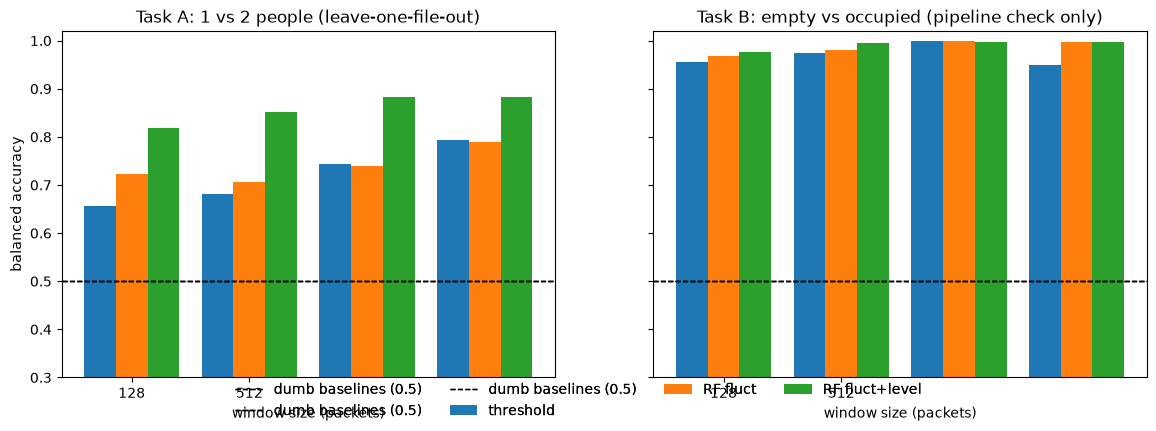

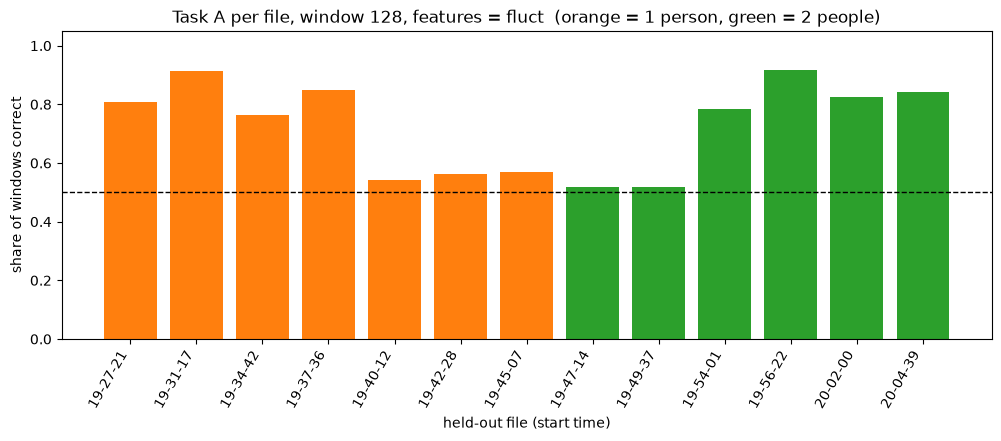

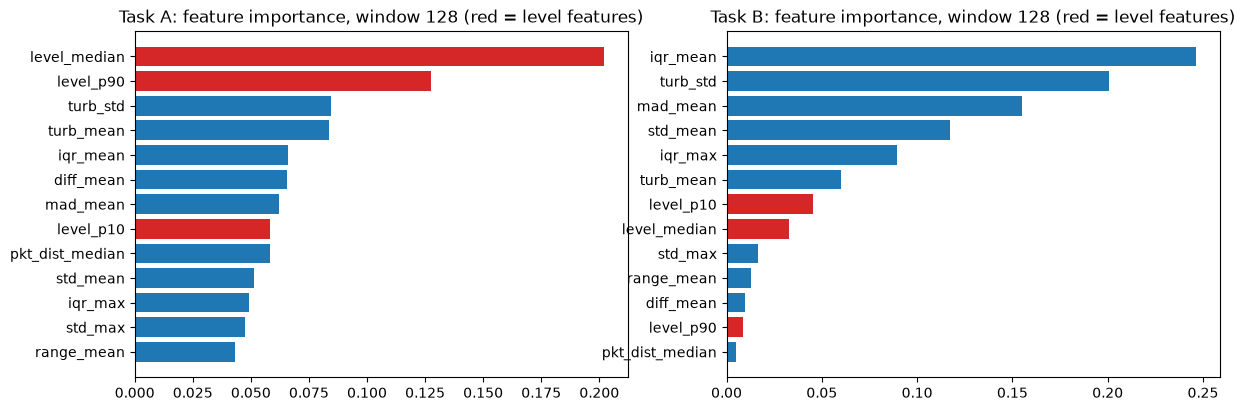

In [51]:
# (1) balanced accuracy per window size; dashed line = what the dumb baselines get (0.5)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, res, title, thr_name in [(axes[0], resA, "Task A: 1 vs 2 people (leave-one-file-out)", "threshold on std_mean"),
                                 (axes[1], resB, "Task B: empty vs occupied (pipeline check only)", "threshold: empty mean+3std")]:
    series = {"threshold": res[res["model"] == thr_name],
              "RF fluct": res[(res["model"] == "random forest") & (res["features"] == "fluct")],
              "RF fluct+level": res[(res["model"] == "random forest") & (res["features"] == "fluct+level")]}
    x = np.arange(len(WINDOW_SIZES))
    for k, (label, s) in enumerate(series.items()):
        pos = np.arange(len(s))
        ax.bar(pos + (k - 1) * 0.27, s["bal_acc"].to_numpy(), width=0.27, label=label)
        ax.axhline(0.5, color="k", ls="--", lw=1, label="dumb baselines (0.5)")
        ax.set_xticks(x); ax.set_xticklabels(WINDOW_SIZES); ax.set_xlabel("window size (packets)")
        ax.set_ylim(0.3, 1.02); ax.set_title(title)
        axes[0].set_ylabel("balanced accuracy")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
# plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.savefig(FIGS / "04_baselines_summary.png", dpi=150); plt.show()

# (2) Task A: share of correct windows per held-out file
d, y, pred = predsA[(WIN_SHOW, FS_SHOW)]
pf = (pd.DataFrame({"file": d["file_id"].str[:19], "people": d["label"], "ok": pred == y})
      .groupby(["file", "people"], as_index=False)["ok"].mean())
fig, ax = plt.subplots(figsize=(12, 4))
colors = pf["people"].map({1: "tab:orange", 2: "tab:green"})
ax.bar(range(len(pf)), pf["ok"], color=colors)
ax.set_xticks(range(len(pf))); ax.set_xticklabels(pf["file"].str[11:], rotation=60, ha="right")
ax.axhline(0.5, color="k", ls="--", lw=1); ax.set_ylim(0, 1.05)
ax.set_ylabel("share of windows correct"); ax.set_xlabel("held-out file (start time)")
ax.set_title(f"Task A per file, window {WIN_SHOW}, features = {FS_SHOW}  (orange = 1 person, green = 2 people)")
# plt.tight_layout(); plt.savefig(FIGS / "05_taskA_per_file.png", dpi=150); plt.show()

# (3) which features the forest used (mean over folds), with the level features included
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, imp, title in [(axes[0], impA, "Task A"), (axes[1], impB, "Task B")]:
    s = pd.Series(imp[(WIN_SHOW, "fluct+level")], index=FLUCT + LEVEL).sort_values()
    ax.barh(s.index, s.values, color=["tab:red" if n in LEVEL else "tab:blue" for n in s.index])
    ax.set_title(f"{title}: feature importance, window {WIN_SHOW} (red = level features)")
# plt.tight_layout(); plt.savefig(FIGS / "06_feature_importance.png", dpi=150); plt.show()

REPORTS = Path("../reports")    

# (4) save the tables
resA.assign(task="A").to_csv(REPORTS / "phase1_results_taskA.csv", index=False)
resB.assign(task="B").to_csv(REPORTS / "phase1_results_taskB.csv", index=False)
print("saved tables to", REPORTS)

In [35]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import json, time
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix



WINDOW_SIZES = [128,512]
EPOCHS  = 25
BATCH_SIZE = 32
SEED = 0
keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__, keras.__version__)

TensorFlow version: 2.21.0 3.15.1


In [32]:
def load_windows(win):
    idx = pd.read_csv(out / f"windows_index_{win}.csv")
    idx = idx[idx["label"].isin([1, 2])].reset_index(drop=True)          # keep 1-person and 2-person windows
    amp = {f: np.load(out / f.replace(".csv", ".npz"))["amp"] for f in idx["file_id"].unique()}
    X = np.stack([amp[f][s:s + win] for f, s in zip(idx["file_id"], idx["start"])]).astype(np.float32)
    y = (idx["label"] == 2).to_numpy().astype(np.float32)                # 0 = one person, 1 = two people
    groups = idx["file_id"].to_numpy()                                   # which file each window came from
    return X, y, groups

data = {w: load_windows(w) for w in WINDOW_SIZES}
for w, (X, y, g) in data.items():
    print(f"window {w}: X shape {X.shape} = (windows, packets, subcarriers) | "
          f"1 person: {int((y == 0).sum())}, 2 people: {int((y == 1).sum())}, files: {len(np.unique(g))}")

window 128: X shape (1051, 128, 52) = (windows, packets, subcarriers) | 1 person: 561, 2 people: 490, files: 13
window 512: X shape (251, 512, 52) = (windows, packets, subcarriers) | 1 person: 134, 2 people: 117, files: 13


In [54]:
from numpy.lib.stride_tricks import sliding_window_view

def hampel_causal(X, k=5, n_sigmas=3.0):
    """Replace a packet by the median of the last k packets if it is a spike. Uses only PAST packets."""
    pad = np.repeat(X[:, :1, :], k, axis=1)
    Xp = np.concatenate([pad, X], axis=1)
    W = sliding_window_view(Xp, k + 1, axis=1)[:, :X.shape[1]]
    med = np.median(W, axis=-1)
    mad = np.median(np.abs(W - med[..., None]), axis=-1)
    bad = np.abs(X - med) > n_sigmas * 1.4826 * mad
    return np.where(bad, med, X).astype(np.float32)

def smooth_causal(X, k=4):
    """Moving average of the last k packets (a simple low-pass filter)."""
    pad = np.repeat(X[:, :1, :], k - 1, axis=1)
    Xp = np.concatenate([pad, X], axis=1)
    return sliding_window_view(Xp, k, axis=1)[:, :X.shape[1]].mean(axis=-1).astype(np.float32)

FILTER = "none"   # "none" | "hampel" | "smooth" | "both"

def apply_filter(X):
    if FILTER in ("hampel", "both"): X = hampel_causal(X)
    if FILTER in ("smooth", "both"): X = smooth_causal(X)
    return X

def remove_level(X):
    return apply_filter(X) - apply_filter(X).mean(axis=1, keepdims=True)

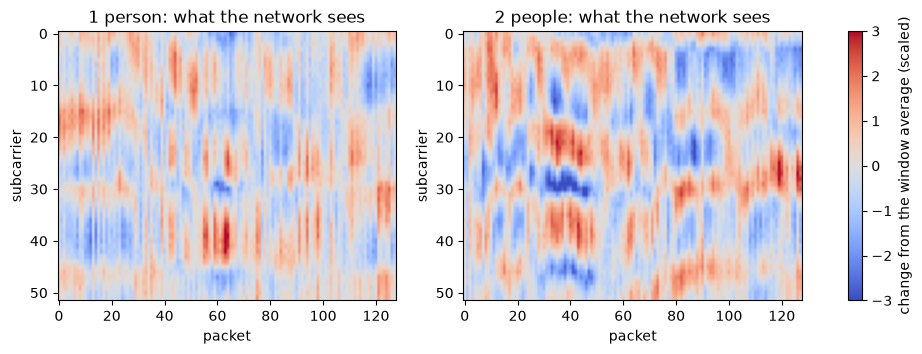

In [58]:
# def remove_level(X):
#     return X - X.mean(axis=1, keepdims=True)          # axis 1 = time (packets)

def fit_scale(X_train):
    """One number: the typical size of the changes in the TRAINING windows."""
    return float(remove_level(X_train).std())

def prepare(X, scale):
    """Window -> level removed -> divided by the scale, so values are mostly between -3 and 3."""
    return (remove_level(X) / scale).astype(np.float32)

# Look at one 1-person and one 2-person window after preparing them (demo only)
X, y, g = data[128]
scale_demo = fit_scale(X)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, cls, title in [(axes[0], 0, "1 person"), (axes[1], 1, "2 people")]:
    w0 = prepare(X[y == cls][5:6], scale_demo)[0]                         # one window: (128, 52)
    im = ax.imshow(w0.T, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
    ax.set_title(f"{title}: what the network sees"); ax.set_xlabel("packet"); ax.set_ylabel("subcarrier")
fig.colorbar(im, ax=axes, label="change from the window average (scaled)")
# plt.savefig(FIGS / "07_network_input.png", dpi=150, bbox_inches="tight"); plt.show()

In [34]:
def build_cnn(win):
    model = keras.Sequential([
        keras.Input(shape=(win,52)),

        layers.Conv1D(8, 5 , activation="relu"),
        layers.MaxPooling1D(4),

        layers.Conv1D(16, 5, activation="relu"),
        layers.GlobalAveragePooling1D(),

        layers.Dropout(0.3),

        layers.Dense(1, activation="sigmoid")


    ])

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss="binary_crossentropy", metrics=["accuracy"])
    return model

build_cnn(128).summary()
    

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 8)         │         2,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 31, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 27, 16)         │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,761 (10.79 KB)

 Trainable params: 2,761 (10.79 KB)

 Non-trainable params: 0 (0.00 B)

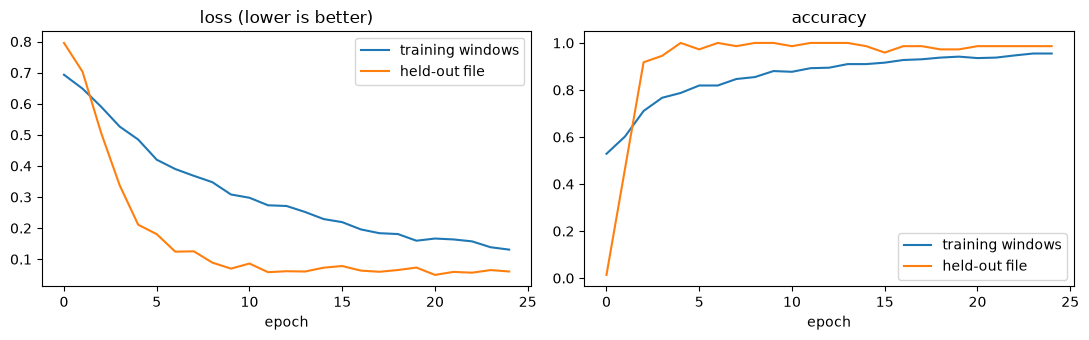

held-out file 2023-12-21_19-27-21 (1 people): accuracy 0.99, training accuracy 0.96


In [36]:
def class_weights(y):
    n, n1 = len(y), float(y.sum()); n0 = n - n1
    return {0: n / (2 * n0), 1: n / (2 * n1)}            # the rarer class counts a little more

w = 128
X, y, g = data[w]
test_file = np.unique(g)[0]                              # try np.unique(g)[5], [10], ... too
test = g == test_file
scale = fit_scale(X[~test])

keras.utils.set_random_seed(SEED)
model = build_cnn(w)
hist = model.fit(prepare(X[~test], scale), y[~test], epochs=EPOCHS, batch_size=BATCH_SIZE,
                 class_weight=class_weights(y[~test]),
                 validation_data=(prepare(X[test], scale), y[test]), verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(hist.history["loss"], label="training windows"); axes[0].plot(hist.history["val_loss"], label="held-out file")
axes[0].set_title("loss (lower is better)"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist.history["accuracy"], label="training windows"); axes[1].plot(hist.history["val_accuracy"], label="held-out file")
axes[1].set_title("accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout() 
plt.show()
# plt.savefig(FIGS / "08_one_training_run.png", dpi=150)
print(f"held-out file {test_file[:19]} ({int(y[test][0]) + 1} people): "
      f"accuracy {hist.history['val_accuracy'][-1]:.2f}, training accuracy {hist.history['accuracy'][-1]:.2f}")

In [59]:
def metrics(y, pred, score):
    y = y.astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])
    return {"bal_acc": balanced_accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
            "auc": roc_auc_score(y, score),
            "rec_1p": cm[0, 0] / cm[0].sum(), "rec_2p": cm[1, 1] / cm[1].sum()}

def cnn_leave_one_file_out(X, y, groups, win):
    """Train on all files except one, test on that file. Repeat for every file."""
    score = np.zeros(len(y))
    for f in np.unique(groups):
        test = groups == f
        scale = fit_scale(X[~test])                       # scale comes from the TRAINING files only
        keras.utils.set_random_seed(SEED)
        model = build_cnn(win)
        model.fit(prepare(X[~test], scale), y[~test], epochs=EPOCHS, batch_size=BATCH_SIZE,
                  class_weight=class_weights(y[~test]), verbose=0)
        score[test] = model(prepare(X[test], scale), training=False).numpy().ravel()
        keras.backend.clear_session()                     # free memory between folds
    return (score > 0.5).astype(int), score

rows_cnn, preds_cnn = [], {}
for w in WINDOW_SIZES:
    X, y, g = data[w]
    t0 = time.time()
    pred, score = cnn_leave_one_file_out(X, y, g, w)
    preds_cnn[w] = (y.astype(int), pred, g)
    rows_cnn.append({"win": w, "model": "tiny CNN", "features": "raw window, level removed", **metrics(y, pred, score)})
    print(f"window {w}: finished in {time.time() - t0:.0f} s")

window 128: finished in 99 s
window 512: finished in 71 s


In [60]:
REPORTS = Path("../reports/Wicount") 

ref = pd.read_csv(REPORTS / "phase1_results_taskA.csv")
ref = ref[ref["win"].isin(WINDOW_SIZES) & ref["features"].isin(["-", "std_mean", "fluct"])]
table = pd.concat([ref.drop(columns="task"), pd.DataFrame(rows_cnn)], ignore_index=True)
order = {"always 1 person": 0, "always 2 people": 1, "threshold on std_mean": 2, "random forest": 3, "tiny CNN": 4}
table = table.sort_values(["win", "model"], key=lambda s: s.map(order) if s.name == "model" else s)
print("TASK A: 1 vs 2 people (leave-one-file-out, 13 files)\n")
print(table.round(3).to_string(index=False))

for w in WINDOW_SIZES:
    y, pred, g = preds_cnn[w]
    print(f"\nCNN, window {w}: share of windows correct per held-out file")
    pf = (pd.DataFrame({"file": [f[:19] for f in g], "true_people": y + 1, "share_correct": pred == y})
          .groupby(["file", "true_people"], as_index=False)["share_correct"].mean())
    print(pf.round(2).to_string(index=False))

TASK A: 1 vs 2 people (leave-one-file-out, 13 files)

 win                 model                  features  bal_acc  macro_f1   auc  rec_1p  rec_2p
 128       always 1 person                         -    0.500     0.348 0.500   1.000   0.000
 128       always 2 people                         -    0.500     0.318 0.500   0.000   1.000
 128 threshold on std_mean                  std_mean    0.657     0.656 0.714   0.652   0.661
 128         random forest                     fluct    0.723     0.722 0.775   0.711   0.735
 128              tiny CNN raw window, level removed    0.820     0.819 0.906   0.813   0.827
 512       always 1 person                         -    0.500     0.348 0.500   1.000   0.000
 512       always 2 people                         -    0.500     0.318 0.500   0.000   1.000
 512 threshold on std_mean                  std_mean    0.744     0.744 0.839   0.761   0.726
 512         random forest                     fluct    0.740     0.740 0.841   0.754   0.726
 512  

In [53]:
MODELS = Path("../models/Wicount")
MODELS.mkdir(parents=True, exist_ok=True)
for w in WINDOW_SIZES:
    X, y, g = data[w]
    scale = fit_scale(X)
    keras.utils.set_random_seed(SEED)
    model = build_cnn(w)
    model.fit(prepare(X, scale), y, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weights(y), verbose=0)
    model.save(MODELS / f"cnn_taskA_win{w}.keras")

    # The preparation is part of the model: the board must do exactly the same.
    (MODELS / f"cnn_taskA_win{w}_preprocess.json").write_text(json.dumps({
        "window_packets": w, "subcarriers": 52,
        "step_1": "subtract, for every subcarrier, its average over the window",
        "step_2": "divide by scale", "scale": scale}, indent=2))

    # 20 example windows and the model's answers, to compare with the board later
    sel = np.linspace(0, len(X) - 1, 20).astype(int)
    np.savez(MODELS / f"dryrun_samples_win{w}.npz", X_raw=X[sel], X_prepared=prepare(X[sel], scale),
             y=y[sel], python_output=model(prepare(X[sel], scale), training=False).numpy().ravel())
    print(f"window {w}: saved model, preprocess.json and 20 test windows to {MODELS}")

window 128: saved model, preprocess.json and 20 test windows to ..\models\Wicount
window 512: saved model, preprocess.json and 20 test windows to ..\models\Wicount


In [62]:
# ---------- Cell 9: convert the saved models to int8 TFLite ----------
def convert_int8(model, X_prepared):
    """Float Keras model -> int8 TFLite bytes. X_prepared = windows after prepare()."""
    conv = tf.lite.TFLiteConverter.from_keras_model(model)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    sel = np.linspace(0, len(X_prepared) - 1, 200).astype(int)           # 200 example windows
    conv.representative_dataset = lambda: ([X_prepared[i:i + 1]] for i in sel)  # each item is a LIST
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8     # the board will feed int8 in
    conv.inference_output_type = tf.int8    # and get int8 out
    return conv.convert()

def make_interpreter(tfl_bytes):
    return tf.lite.Interpreter(
        model_content=tfl_bytes,
        experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)

def run_int8(interp, X_prepared):
    """Run int8 model on many windows. Returns scores between 0 and 1."""
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    s_in, z_in = inp["quantization"]; s_out, z_out = out["quantization"]
    scores = []
    for x in X_prepared:
        q = np.clip(np.round(x[None] / s_in + z_in), -128, 127).astype(np.int8)   # float -> int8
        interp.set_tensor(inp["index"], q); interp.invoke()
        # scores.append((interp.get_tensor(out["index"])[0, 0] - z_out) * s_out)    # int8 -> 0..1
        scores.append((float(interp.get_tensor(out["index"])[0, 0]) - z_out) * s_out)   # int8 -> float first, then 0..1
    return np.array(scores, dtype=np.float32)

rows = []
for w in WINDOW_SIZES:
    X, y, g = data[w]
    info = json.loads((MODELS / f"cnn_taskA_win{w}_preprocess.json").read_text())
    Xp = prepare(X, info["scale"])                                   # SAME preparation as training
    model = keras.models.load_model(MODELS / f"cnn_taskA_win{w}.keras")

    tfl = convert_int8(model, Xp)
    (MODELS / f"cnn_taskA_win{w}_int8.tflite").write_bytes(tfl)

    interp = make_interpreter(tfl); interp.allocate_tensors()
    ops = sorted({d["op_name"] for d in interp._get_ops_details()})
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

    s_float = model(Xp, training=False).numpy().ravel()
    s_int8 = run_int8(interp, Xp)
    rows.append({"win": w, "tflite_KB": round(len(tfl) / 1024, 1), "ops": ", ".join(ops),
                 "input_shape": tuple(inp["shape"]),
                 "same_class_%": round(100 * ((s_float > .5) == (s_int8 > .5)).mean(), 1),
                 "max_score_diff": round(float(np.abs(s_float - s_int8).max()), 3)})

    # The board needs these two numbers to turn its float input into int8
    info.update({"input_scale": float(inp["quantization"][0]), "input_zero_point": int(inp["quantization"][1]),
                 "output_scale": float(out["quantization"][0]), "output_zero_point": int(out["quantization"][1])})
    (MODELS / f"cnn_taskA_win{w}_preprocess.json").write_text(json.dumps(info, indent=2))

print(pd.DataFrame(rows).to_string(index=False))

INFO:tensorflow:Assets written to: C:\Users\Asus\AppData\Local\Temp\tmpqostw95l\assets


INFO:tensorflow:Assets written to: C:\Users\Asus\AppData\Local\Temp\tmpqostw95l\assets


Saved artifact at 'C:\Users\Asus\AppData\Local\Temp\tmpqostw95l'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 52), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2247224245328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247224244944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247203792528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247203792720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247224238992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247224239760: TensorSpec(shape=(), dtype=tf.resource, name=None)


g:\Masters\Sem 3\Capstone\On-Device-WiFi-CSI-Occupancy-Counting-on-an-ESP32-S3-for-Energy-Saving-Smart-Rooms\SmartRoomSense\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
g:\Masters\Sem 3\Capstone\On-Device-WiFi-CSI-Occupancy-Counting-on-an-ESP32-S3-for-Energy-Saving-Smart-Rooms\SmartRoomSense\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


INFO:tensorflow:Assets written to: C:\Users\Asus\AppData\Local\Temp\tmp6s3xfnl5\assets


INFO:tensorflow:Assets written to: C:\Users\Asus\AppData\Local\Temp\tmp6s3xfnl5\assets


Saved artifact at 'C:\Users\Asus\AppData\Local\Temp\tmp6s3xfnl5'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 512, 52), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2247224760592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247224755600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247224760976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247224756752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247224758864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2247224757712: TensorSpec(shape=(), dtype=tf.resource, name=None)


g:\Masters\Sem 3\Capstone\On-Device-WiFi-CSI-Occupancy-Counting-on-an-ESP32-S3-for-Energy-Saving-Smart-Rooms\SmartRoomSense\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
g:\Masters\Sem 3\Capstone\On-Device-WiFi-CSI-Occupancy-Counting-on-an-ESP32-S3-for-Energy-Saving-Smart-Rooms\SmartRoomSense\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


 win  tflite_KB                                                                         ops  input_shape  same_class_%  max_score_diff
 128        8.7 CONV_2D, EXPAND_DIMS, FULLY_CONNECTED, LOGISTIC, MAX_POOL_2D, MEAN, RESHAPE (1, 128, 52)          99.6           0.047
 512        8.9 CONV_2D, EXPAND_DIMS, FULLY_CONNECTED, LOGISTIC, MAX_POOL_2D, MEAN, RESHAPE (1, 512, 52)         100.0           0.012
